# Lab 7 — Physics Engine Prototype

**Name:** Matthew Nallar  
**Date:** October 18, 2026

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import inspect
import lab07_engine


***Part A***

In [2]:
# Implement Classes

from lab07_engine import (
    Body,
    Force,
    Gravity,
    Drag,
    Spring,
    NewtonGravity,
    Euler,
    EulerCromer,
    VelocityVerlet,
    CircleCollisions,
    World
)

print("Engine imported from:", inspect.getfile(lab07_engine))
print("Body constructor:", inspect.signature(Body))
print("World constructor:", inspect.signature(World))

Engine imported from: c:\Users\matth\OneDrive\Documents\GitHub\phys311\labs\lab07\lab07_engine\__init__.py
Body constructor: (m=1.0, r=(0.0, 0.0), v=(0.0, 0.0), radius=0.0, I=None, theta=0.0, omega=0.0, fixed=False, name='')
World constructor: (integrator=None, forces=None, bodies=None, constraints=None)


In [3]:
body = Body(
    m=1.0,
    r=[0.0, 0.0],
    v=[1.0, 0.0],
    radius=0.1
)

print("Mass:", body.m)
print("Position:", body.r)
print("Velocity:", body.v)
print("Kinetic energy:", body.ke())
print("Momentum:", body.p())

Mass: 1.0
Position: [0. 0.]
Velocity: [1. 0.]
Kinetic energy: 0.5
Momentum: [1. 0.]


In [4]:
body = Body(m=2.0, r=[0, 10], v=[0, 0])
world = World(bodies=[body], forces=[Gravity(g=9.81)])

world.compute_forces()

print("Net force:", body.f)


body = Body(m=1.0, r=[0, 0], v=[3, 0])
world = World(bodies=[body], forces=[Drag(k=0.5, quadratic=False)])

world.compute_forces()

print("Drag force:", body.f)

Net force: [  0.   -19.62]
Drag force: [-1.5  0. ]


In [5]:
# Accumulator and Integrator

body = Body(m=1.0, r=[0, 0], v=[0, 0])
world = World(
    bodies=[body],
    forces=[Gravity(g=9.81)],
    integrator=EulerCromer()
)

world.step(0.1)

print("Time:", world.t)
print("Position:", body.r)
print("Velocity:", body.v)

Time: 0.1
Position: [ 0.     -0.0981]
Velocity: [ 0.    -0.981]


In [6]:
body = Body(m=1.0, r=[0, 0], v=[5, 10])

world = World(
    bodies=[body],
    forces=[Gravity(g=9.81)],
    integrator=EulerCromer()
)

# Data-recording mechanism

world.record("time", lambda w: w.t)
world.record("x", lambda w: w.bodies[0].r[0])
world.record("y", lambda w: w.bodies[0].r[1])
world.record("energy", lambda w: w.total_energy())

data = world.run(dt=0.01, t_end=2.0)

print("Recorded quantities:", data.keys())
print("Number of recorded times:", len(data["time"]))
print("Final position:", body.r)

Recorded quantities: dict_keys(['time', 'x', 'y', 'energy'])
Number of recorded times: 201
Final position: [10.      0.2819]


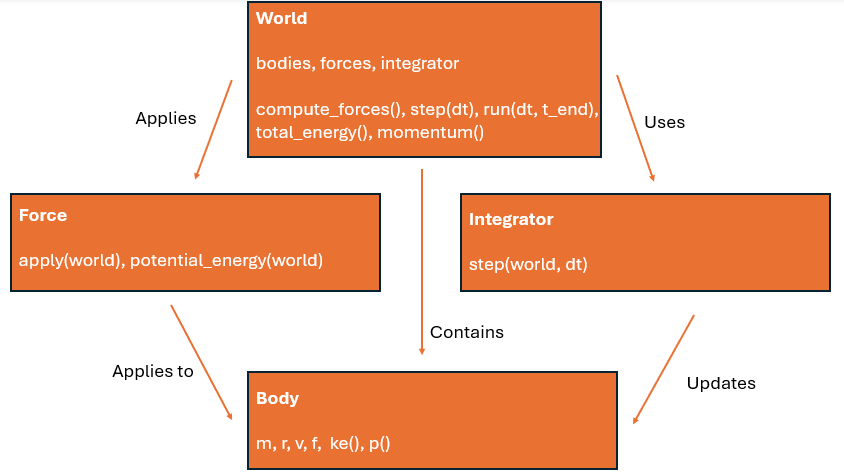

***Part B***

Initial energy: 100.0 J
Final energy: 99.90376390000006 J
Initial horizontal momentum: 10.0
Final horizontal momentum: 10.0


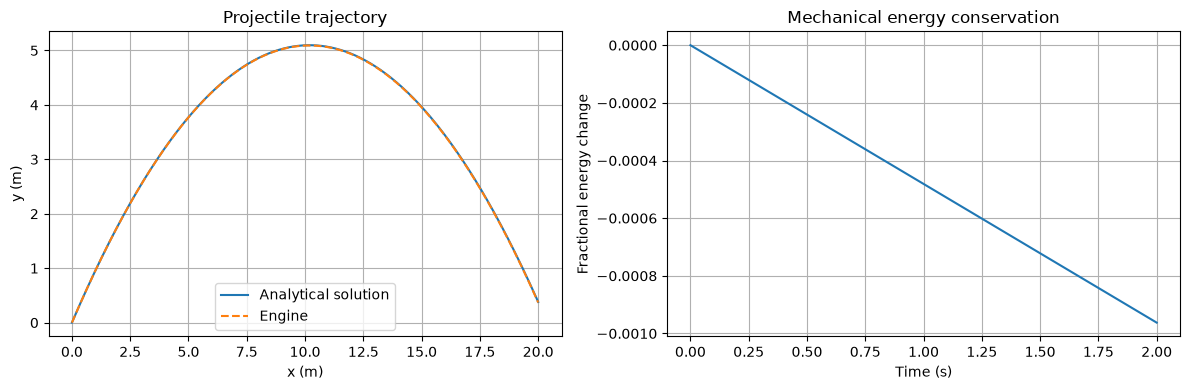

In [7]:
body = Body(m=1.0, r=[0, 0], v=[10, 10])

world = World(
    integrator=EulerCromer(),
    bodies=[body],
    forces=[Gravity(g=9.81)]
)

world.record("time", lambda w: w.t)
world.record("x", lambda w: w.bodies[0].r[0])
world.record("y", lambda w: w.bodies[0].r[1])
world.record("energy", lambda w: w.total_energy())
world.record("px", lambda w: w.momentum()[0])

projectile = world.run(dt=0.001, t_end=2.0)

print("Initial energy:", projectile["energy"][0], "J")
print("Final energy:", projectile["energy"][-1], "J")
print("Initial horizontal momentum:", projectile["px"][0])
print("Final horizontal momentum:", projectile["px"][-1])


t = projectile["time"]

x_exact = 10 * t
y_exact = 10 * t - 0.5 * 9.81 * t**2

energy_change = (
    projectile["energy"] - projectile["energy"][0]
) / abs(projectile["energy"][0])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(x_exact, y_exact, label="Analytical solution")
ax[0].plot(projectile["x"], projectile["y"], "--",
           label="Engine")
ax[0].set_xlabel("x (m)")
ax[0].set_ylabel("y (m)")
ax[0].set_title("Projectile trajectory")
ax[0].legend()
ax[0].grid(True)

ax[1].plot(t, energy_change)
ax[1].set_xlabel("Time (s)")
ax[1].set_ylabel("Fractional energy change")
ax[1].set_title("Mechanical energy conservation")
ax[1].grid(True)

plt.tight_layout()
plt.show()

Theoretical period: 3.141592653589793 s
Initial energy: 2.0 J
Final energy: 1.998513115715867 J


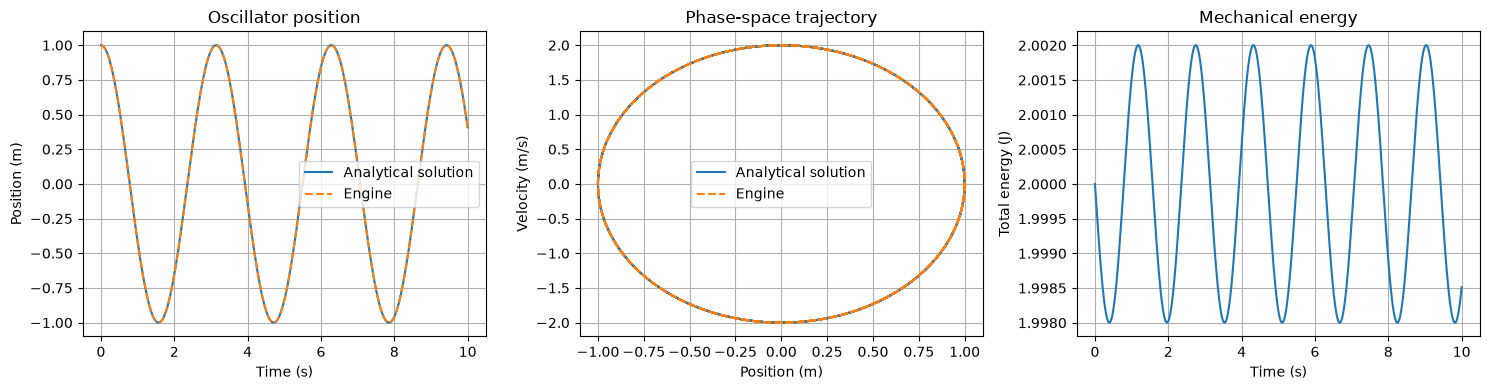

Theoretical period: 3.141592653589793 s
Measured period: 3.1420000000003188 s
Absolute error: 0.00040734641052564413 s


In [8]:
anchor = Body(m=1.0, r=[0, 0], fixed=True)
mass = Body(m=1.0, r=[1, 0], v=[0, 0])

world = World(
    integrator=EulerCromer(),
    bodies=[anchor, mass],
    forces=[Spring(i=0, j=1, k=4.0, L0=0.0)]
)

world.record("time", lambda w: w.t)
world.record("x", lambda w: w.bodies[1].r[0])
world.record("vx", lambda w: w.bodies[1].v[0])
world.record("energy", lambda w: w.total_energy())

oscillator = world.run(dt=0.001, t_end=10.0)

print("Theoretical period:", np.pi, "s")
print("Initial energy:", oscillator["energy"][0], "J")
print("Final energy:", oscillator["energy"][-1], "J")


t = oscillator["time"]

x_exact = np.cos(2 * t)
vx_exact = -2 * np.sin(2 * t)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].plot(t, x_exact, label="Analytical solution")
ax[0].plot(t, oscillator["x"], "--", label="Engine")
ax[0].set_xlabel("Time (s)")
ax[0].set_ylabel("Position (m)")
ax[0].set_title("Oscillator position")
ax[0].legend()
ax[0].grid(True)

ax[1].plot(x_exact, vx_exact, label="Analytical solution")
ax[1].plot(oscillator["x"], oscillator["vx"], "--",
           label="Engine")
ax[1].set_xlabel("Position (m)")
ax[1].set_ylabel("Velocity (m/s)")
ax[1].set_title("Phase-space trajectory")
ax[1].legend()
ax[1].grid(True)

ax[2].plot(t, oscillator["energy"])
ax[2].set_xlabel("Time (s)")
ax[2].set_ylabel("Total energy (J)")
ax[2].set_title("Mechanical energy")
ax[2].grid(True)

plt.tight_layout()
plt.show()


x = oscillator["x"]
t = oscillator["time"]

crossings = np.where((x[:-1] < 0) & (x[1:] >= 0))[0]

period_measured = t[crossings[1]] - t[crossings[0]]

print("Theoretical period:", np.pi, "s")
print("Measured period:", period_measured, "s")
print("Absolute error:", abs(period_measured - np.pi), "s")

Initial energy: -0.6799999999999999
Final energy: -0.6799999998678754
Initial angular momentum: 0.8
Final angular momentum: 0.799999999999999


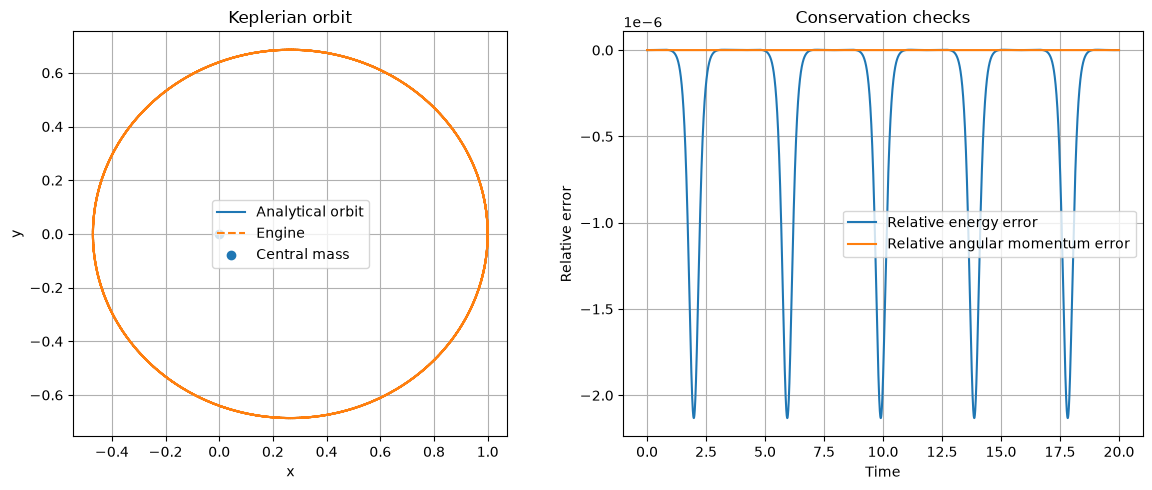

In [9]:
central = Body(m=1.0, r=[0, 0], v=[0, 0], fixed=True)
satellite = Body(m=1.0, r=[1, 0], v=[0, 0.8])

world = World(
    integrator=VelocityVerlet(),
    bodies=[central, satellite],
    forces=[NewtonGravity(G=1.0)]
)

world.record("time", lambda w: w.t)
world.record("x", lambda w: w.bodies[1].r[0])
world.record("y", lambda w: w.bodies[1].r[1])
world.record("energy", lambda w: w.total_energy())
world.record("angular_momentum", lambda w: w.angular_momentum())

orbit = world.run(dt=0.001, t_end=20.0)

print("Initial energy:", orbit["energy"][0])
print("Final energy:", orbit["energy"][-1])
print("Initial angular momentum:", orbit["angular_momentum"][0])
print("Final angular momentum:", orbit["angular_momentum"][-1])


theta = np.linspace(0, 2 * np.pi, 1000)

e = 0.36
p = 0.64
r_exact = p / (1 - e * np.cos(theta))

x_exact = r_exact * np.cos(theta)
y_exact = r_exact * np.sin(theta)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].plot(x_exact, y_exact, label="Analytical orbit")
ax[0].plot(orbit["x"], orbit["y"], "--", label="Engine")
ax[0].scatter([0], [0], label="Central mass")
ax[0].set_xlabel("x")
ax[0].set_ylabel("y")
ax[0].set_title("Keplerian orbit")
ax[0].set_aspect("equal", adjustable="box")
ax[0].legend()
ax[0].grid(True)

relative_energy_error = (
    orbit["energy"] - orbit["energy"][0]
) / abs(orbit["energy"][0])

relative_L_error = (
    orbit["angular_momentum"] - orbit["angular_momentum"][0]
) / abs(orbit["angular_momentum"][0])

ax[1].plot(orbit["time"], relative_energy_error,
           label="Relative energy error")
ax[1].plot(orbit["time"], relative_L_error,
           label="Relative angular momentum error")
ax[1].set_xlabel("Time")
ax[1].set_ylabel("Relative error")
ax[1].set_title("Conservation checks")
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()

***Part C***

In [10]:
import numpy as np
import matplotlib.pyplot as plt

from lab07_engine import (
    Body, Gravity, Drag, Spring, EulerCromer, World
)

# Physical parameters
m1 = 1.0
m2 = 1.0
k = 30.0
L0 = 1.0
g = 9.81

# Fixed anchor
y_anchor = 5.0
anchor = Body(
    m=1.0,
    r=[0.0, y_anchor],
    fixed=True,
    name="Anchor"
)

# Calculate static equilibrium positions
y1_eq = y_anchor - (L0 + (m1 + m2) * g / k)
y2_eq = y1_eq - (L0 + m2 * g / k)

# Top mass starts at equilibrium
mass1 = Body(
    m=m1,
    r=[0.0, y1_eq],
    v=[0.0, 0.0],
    name="Mass 1"
)

# Bottom mass is displaced 2 m downward from equilibrium
mass2 = Body(
    m=m2,
    r=[0.0, y2_eq - 2.0],
    v=[0.0, 0.0],
    name="Mass 2"
)

bodies = [anchor, mass1, mass2]

# Two springs, gravity, and drag
forces = [
    Gravity(g=g),
    Drag(k=0.15, quadratic=False),
    Spring(i=0, j=1, k=k, L0=L0),
    Spring(i=1, j=2, k=k, L0=L0)
]

world = World(
    integrator=EulerCromer(),
    bodies=bodies,
    forces=forces
)

print(f"Anchor position: {y_anchor:.3f} m")
print(f"Mass 1 equilibrium: {y1_eq:.3f} m")
print(f"Mass 2 equilibrium: {y2_eq:.3f} m")
print(f"Mass 2 initial position: {mass2.r[1]:.3f} m")

Anchor position: 5.000 m
Mass 1 equilibrium: 3.346 m
Mass 2 equilibrium: 2.019 m
Mass 2 initial position: 0.019 m


In [14]:
world.record("time", lambda w: w.t)

world.record("y1", lambda w: w.bodies[1].r[1])
world.record("y2", lambda w: w.bodies[2].r[1])

world.record("v1", lambda w: w.bodies[1].v[1])
world.record("v2", lambda w: w.bodies[2].v[1])

world.record("kinetic", lambda w: w.kinetic_energy())
world.record("potential", lambda w: w.potential_energy())
world.record("energy", lambda w: w.total_energy())

data = world.run(dt=0.001, t_end=15.0)

print("Number of recorded time points:", len(data["time"]))

Number of recorded time points: 15001


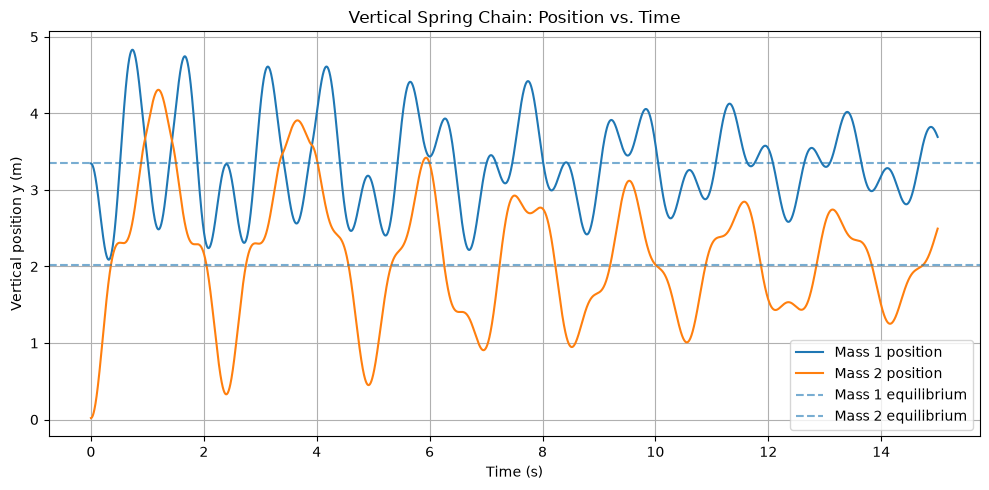

In [12]:
t = data["time"]

plt.figure(figsize=(10, 5))

plt.plot(t, data["y1"], label="Mass 1 position")
plt.plot(t, data["y2"], label="Mass 2 position")

plt.axhline(y1_eq, linestyle="--", alpha=0.6,
            label="Mass 1 equilibrium")
plt.axhline(y2_eq, linestyle="--", alpha=0.6,
            label="Mass 2 equilibrium")

plt.xlabel("Time (s)")
plt.ylabel("Vertical position y (m)")
plt.title("Vertical Spring Chain: Position vs. Time")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [13]:
initial_energy = data["energy"][0]
final_energy = data["energy"][-1]

energy_change = final_energy - initial_energy
energy_change_percent = 100 * energy_change / abs(initial_energy)

print(f"Initial mechanical energy: {initial_energy:.6f} J")
print(f"Final mechanical energy:   {final_energy:.6f} J")
print(f"Energy change:             {energy_change:.6f} J")
print(f"Percentage change:         {energy_change_percent:.3f}%")

Initial mechanical energy: 120.650325 J
Final mechanical energy:   67.261939 J
Energy change:             -53.388386 J
Percentage change:         -44.251%


This simulation models two 1 kg masses connected vertically by two springs with stiffness 30 N/m, with the upper spring attached to a fixed anchor. Gravity acts on both masses, and linear drag dissipates energy. The system is initialized at static equilibrium under gravity, after which the bottom mass is displaced 2 m downward and released from rest.

The lower mass is initially displaced 2 m (without displacing the upper mass) and creates an upward restoring force. As the bottom mass moves, the upper spring transmits the disturbance to the top mass, producing coupled oscillations. Position and velocity plots show how the two masses respond over time. The total mechanical energy generally decreases because of damping, while momentum is not conserved due to gravity and the fixed support.

This scene demonstrates how the physics engine combines multiple bodies, interacting springs, external forces, numerical integration, and energy tracking.